# TP2 — RNN sur série temporelle

**Cours :** Réseaux de neurones récurrents (RNN) — 20 h — Master 1 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 2 h · **Barème :** 10 points

---

## Objectifs

- Écrire la cellule récurrente à la main.
- Mesurer l'évanouissement du gradient.
- Entraîner un RNN à prédire une série.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter les cellules dans l'ordre. Tout tourne sur **CPU** (quelques minutes).
- Les cellules **« À vous »** sont évaluées.
- Graines fixées : deux exécutions donnent le même résultat.

In [1]:
%matplotlib inline
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
torch.manual_seed(4112); np.random.seed(4112)
torch.set_num_threads(2)
print('torch', torch.__version__)

torch 2.15.0+cpu


## 1. La cellule récurrente, écrite à la main

Avant PyTorch, on écrit l'équation : $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$.

In [2]:
E, H = 1, 16
Wx = nn.Linear(E, H)
Wh = nn.Linear(H, H, bias=False)
b = nn.Parameter(torch.zeros(H))

def cellule(x_t, h_pre):
    return torch.tanh(Wx(x_t) + Wh(h_pre) + b)

h = torch.zeros(H)
for k in range(5):
    h = cellule(torch.tensor([0.3]), h)
print("etat apres 5 pas :", h[:4].detach().numpy().round(3))
print("norme de h       :", round(float(h.norm()), 3), "(borne par tanh)")

etat apres 5 pas : [-0.161  0.464 -0.034 -0.083]
norme de h       : 1.694 (borne par tanh)


C:\Users\HP\AppData\Local\Temp\ipykernel_14456\3669397156.py:13: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  print("norme de h       :", round(float(h.norm()), 3), "(borne par tanh)")


## 2. Le gradient s'évanouit : mesure

On propage un gradient à travers $T$ pas et on mesure sa norme.

In [3]:
def norme_gradient(T, rayon):
    torch.manual_seed(4112)
    w = nn.Parameter(torch.tensor(rayon))
    h = torch.tensor(1.0)
    for _ in range(T):
        h = torch.tanh(w * h)
    h.backward()
    return float(w.grad)

for T in (5, 10, 20, 40):
    g = norme_gradient(T, 0.55)
    print(f"T={T:3d}   |d h_T / d w| = {g:.3e}")

T=  5   |d h_T / d w| = 3.758e-01
T= 10   |d h_T / d w| = 3.913e-02
T= 20   |d h_T / d w| = 2.016e-04
T= 40   |d h_T / d w| = 2.609e-09


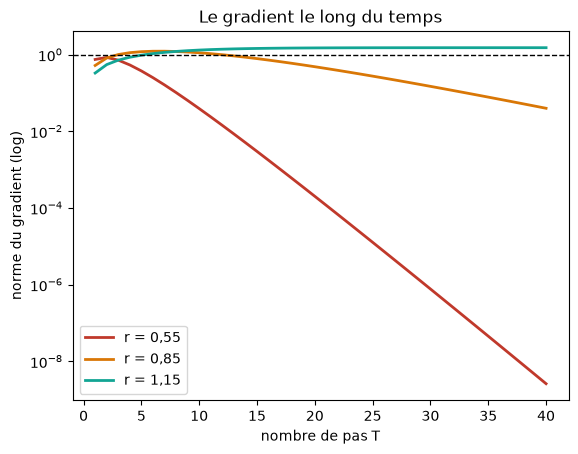

In [4]:
Ts = np.arange(1, 41)
for rayon, coul, lbl in [(0.55, "#C0392B", "r = 0,55"),
                         (0.85, "#D97706", "r = 0,85"),
                         (1.15, "#12A594", "r = 1,15")]:
    plt.semilogy(Ts, [abs(norme_gradient(int(T), rayon)) for T in Ts],
                 color=coul, lw=2, label=lbl)
plt.axhline(1, color="k", ls="--", lw=1)
plt.xlabel("nombre de pas T"); plt.ylabel("norme du gradient (log)")
plt.title("Le gradient le long du temps")
plt.legend(); plt.show()

## 3. Entraîner un RNN à prédire une série

In [5]:
t = np.arange(400)
serie = np.sin(2 * np.pi * t / 40) + 0.15 * np.random.default_rng(4112).normal(size=400)
serie = (serie - serie.mean()) / serie.std()
X = torch.tensor(serie[:-1], dtype=torch.float32).view(1, -1, 1)
Y = torch.tensor(serie[1:], dtype=torch.float32).view(1, -1, 1)

class RNN(nn.Module):
    def __init__(self, H=32):
        super().__init__()
        self.rnn = nn.RNN(1, H, batch_first=True)
        self.out = nn.Linear(H, 1)
    def forward(self, x):
        h, _ = self.rnn(x)
        return self.out(h)

modele = RNN()
opt = torch.optim.Adam(modele.parameters(), lr=1e-2)
perte_f = nn.MSELoss()
for ep in range(60):
    opt.zero_grad()
    pred = modele(X)[:, :-1, :]
    perte = perte_f(pred, Y[:, :-1, :])
    perte.backward()
    torch.nn.utils.clip_grad_norm_(modele.parameters(), 5.0)
    opt.step()
    if ep % 15 == 0:
        print(f"epoque {ep:2d}  perte = {perte.item():.5f}")
print("perte finale :", round(float(perte), 5))

epoque  0  perte = 1.08610


epoque 15  perte = 0.09653


epoque 30  perte = 0.06918


epoque 45  perte = 0.05565


perte finale : 0.05105


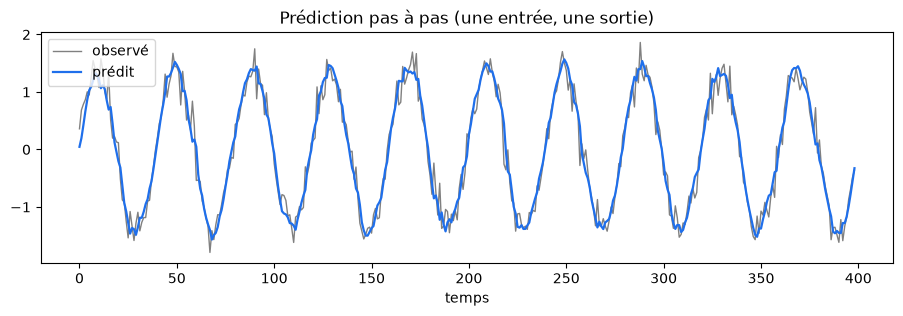

RMSE : 0.2253


In [6]:
with torch.no_grad():
    pred = modele(X)[0, :, 0].numpy()
plt.figure(figsize=(11, 3))
plt.plot(serie[1:], label="observé", color="grey", lw=1)
plt.plot(pred, label="prédit", color="#1F6FEB", lw=1.6)
plt.legend(); plt.title("Prédiction pas à pas (une entrée, une sortie)")
plt.xlabel("temps"); plt.show()
print("RMSE :", round(float(np.sqrt(np.mean((pred - serie[1:])**2))), 4))

## 4. À vous

**1.** Remplacez `nn.RNN` par une cellule écrite à la main et réentraînez. La perte finale est-elle comparable ?

**2.** Supprimez le `clip_grad_norm_` : que devient la perte ?

**3.** Augmentez la période de la sinusoïde (80 au lieu de 40) : le RNN simple y arrive-t-il encore ?

In [7]:
# ---- A VOUS ----
# 1)
# 2)
# 3)

## 5. Synthèse

| Observation | Interprétation |
|---|---|
| norme du gradient ↓ très vite | évanouissement |
| norme ↑ | explosion, à clipper |
| RNN correct sur période courte | mémoire effective limitée |